## Этап 1. Загрузка и подготовка данных 
Загрузите данные из файла. Выполните первичный анализ структуры: определите, сколько записей содержит датасет, какие колонки присутствуют, какие типы данных в них хранятся. Обратите внимание, что данные представлены в широком формате, где каждый год — отдельная колонка, а каждая строка соответствует одному региону. Преобразуйте данные из широкого формата в длинный: одна строка должна соответствовать сочетанию «регион — год», а значение показателя должно находиться в отдельной колонке. После преобразования сформируйте отдельный временной ряд для каждого региона, где индексом является год, а значениями — соответствующие показатели потребления. 
В файле есть пропуски: часть из них обозначена пустыми ячейками, часть — символом «…». Из-за этого числовые столбцы при загрузке могут считываться как текстовые. Приведите годовые показатели к числовому формату, заменив специальные обозначения на пропуски. У разных территорий разная глубина исторических данных: у Крыма и Севастополя отсутствуют значения за 14 лет, у некоторых агрегированных записей — за 11 лет. Для основного анализа используйте только территории с полным рядом данных за весь доступный период (2000–2023 годы). Не восстанавливайте длительные начальные фрагменты ряда интерполяцией или экстраполяцией. В отчёте перечислите исключённые территории и объясните причины их исключения.

In [15]:
from pathlib import Path
import pandas as pd
from numpy import isin
import seaborn as sns
import numpy as np

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import silhouette_samples
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer,RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import RobustScaler
from scipy.cluster.hierarchy import dendrogram

In [16]:
datapath = Path('data')
datapath.mkdir(exist_ok=True)
file_name = 'rsdocs_1491005410458_wide_appendix_2025.csv'
df = pd.read_csv(datapath / file_name,
                encoding='utf-8',
                dtype=str,
                na_values=['…', ''])


Для кластеризации и прогнозирования используйте только субъекты Российской Федерации. Исключите из анализа строки, соответствующие Российской Федерации в целом, федеральным округам, а также дублирующиеся агрегированные записи (например, Тюменская область без автономных округов). Работу нужно выполнять с данными по конкретным регионам, а не по их агрегатам.

In [17]:
rows_to_drop = [
    'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
    'Архангельская область без автономного округа',
    'Тюменская область без автономных округов',
    'Республика Крым',
    'г. Севастополь'
]

df = df.loc[~df['region_name'].isin(rows_to_drop)]
df = df.loc[~df['region_name'].str.contains('федераль')]


In [18]:
df['region_name'].unique().tolist()

['Белгородская область',
 'Брянская область',
 'Владимирская область',
 'Воронежская область',
 'Ивановская область',
 'Калужская область',
 'Костромская область',
 'Курская область',
 'Липецкая область',
 'Московская область',
 'Орловская область',
 'Рязанская область',
 'Смоленская область',
 'Тамбовская область',
 'Тверская область',
 'Тульская область',
 'Ярославская область',
 'г. Москва',
 'Республика Карелия',
 'Республика Коми',
 'Архангельская область',
 'Ненецкий автономный округ',
 'Вологодская область',
 'Калинингpадская область',
 'Ленинградская область',
 'Мурманская область',
 'Новгородская область',
 'Псковская область',
 'г. Санкт-Петербург',
 'Республика Адыгея',
 'Республика Калмыкия',
 'Краснодарский край',
 'Астраханская область',
 'Волгоградская область',
 'Ростовская область',
 'Республика Дагестан',
 'Республика Ингушетия',
 'Кабардино-Балкарская Республика',
 'Карачаево-Черкесская Республика',
 'Республика Северная Осетия – Алания',
 'Чеченская Республика',
 'С

In [19]:
df_long = pd.melt(
    df,
    id_vars= ['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # колонки, которые нужно сохранить
    value_vars=[str(year) for year in range(2000, 2024)],  # только годовые колонки
    var_name='year',  # имя для новой колонки с названиями (по умолчанию 'variable')
    value_name="value",  # имя для новой колонки со значениями (по умолчанию 'value')
    ignore_index=True,  # сбрасывать ли индекс (по умолчанию True)
)
df_long = df_long[['region_name', 'year','value']]
df_long['value'] = pd.to_numeric(
    df_long['value'].str.replace(',', '.', regex=False), errors='coerce'
)
# Оставляем целые ряды: удаление отдельных пропусков искажает годовую динамику.
incomplete = df_long.groupby('region_name')['value'].apply(lambda s: s.isna().any())
excluded_regions = incomplete[incomplete].index.tolist()
print('Исключены регионы с неполными рядами:', excluded_regions)
df_long = df_long.loc[~df_long['region_name'].isin(excluded_regions)].copy()
df_long = df_long.sort_values(['region_name','year']).reset_index(drop=True)
df_long['year'] = df_long['year'].astype(int)

Исключены регионы с неполными рядами: ['Ненецкий автономный округ', 'Ханты-Мансийский автономный округ – Югра', 'Чеченская Республика', 'Ямало-Ненецкий автономный округ']


## Этап 2. Кластерный анализ регионов 
Чтобы сгруппировать регионы по схожести динамики показателя, вам потребуется выполнить кластеризацию. Вы можете использовать K-means или любой другой алгоритм кластеризации, с которым вы знакомы по курсу машинного обучения (например, агломеративную иерархическую кластеризацию). Выбор конкретного метода остаётся за вами; в отчёте нужно обосновать, почему вы выбрали именно этот алгоритм. В описании этапа ниже приведены рекомендации для K-means, но вы можете адаптировать их под выбранный метод.
На основе агрегированных характеристик временных рядов разделите все регионы на несколько групп. Для этого для каждого региона извлеките признаки, характеризующие его временной ряд. Учтите, что данные представлены в текущих ценах, поэтому абсолютные показатели (среднее значение, стандартное отклонение) в значительной степени отражают масштаб экономики региона и общий рост цен, а не специфику его динамики. Чтобы кластеризация выделяла регионы со сходными траекториями развития, а не просто регионы со сходным уровнем потребления, используйте набор признаков, включающий как минимум один относительный показатель динамики.
Рекомендуемый набор признаков для каждого региона (выберите не менее четырёх):
    • среднее значение за период (отражает общий уровень потребления в регионе);
    • коэффициент вариации (стандартное отклонение, делённое на среднее — характеризует относительную волатильность ряда, не зависящую от масштаба);
    • средний годовой темп роста (или медианный темп роста);
    • относительное изменение за весь период (значение в последнем году относительно первого);
    • максимальное годовое падение (наибольшее отрицательное изменение за один год);
    • доля лет с отрицательной динамикой (число лет, когда показатель снизился относительно предыдущего года).
Этот набор позволит выделить регионы не только по уровню потребления, но и по характеру его изменения: где рост устойчив, где он сменяется падением, где динамика более волатильна, где более стабильна. 
После извлечения признаков выполните их стандартизацию, затем проведите кластеризацию. Рассмотрите варианты от двух до четырёх кластеров. Для каждого варианта рассчитайте silhouette score и оцените содержательную интерпретируемость полученных групп. Выберите оптимальное число кластеров на основе совокупности этих двух критериев — числовой метрики и экономического смысла. Силуэт сам по себе не является достаточным основанием для выбора, если полученные группы трудно интерпретировать. В отчёте обоснуйте свой выбор: приведите значения silhouette score для каждого варианта и объясните, почему выбранное число кластеров лучше других с точки зрения содержательной интерпретации.
Для каждого кластера дайте содержательное описание: какие регионы в него попали, каков средний уровень потребления, какие особенности динамики характерны для этой группы.

In [ ]:
from sklearn.preprocessing import QuantileTransformer

# Используем те же четыре признака, что и в варианте StandardScaler выше.
X_dynamics = region_stats[feature_columns]
rank_scaler = QuantileTransformer(
    n_quantiles=len(X_dynamics),
    output_distribution='uniform',
    random_state=1,
)
X_rank = rank_scaler.fit_transform(X_dynamics)
pca_rank = PCA(n_components=0.95)
X_rank_pca = pca_rank.fit_transform(X_rank)
print(f'Компонент PCA: {pca_rank.n_components_}; '
      f'сохранено дисперсии: {pca_rank.explained_variance_ratio_.sum():.2%}')

comparison = []
for space_name, features in [
    ('StandardScaler + PCA', X_scaled),
    ('Ранги + PCA', X_rank_pca),
]:
    for k in [2, 3, 4]:
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(features)
        sizes = pd.Series(labels).value_counts().sort_index()
        comparison.append({
            'Преобразование': space_name,
            'k': k,
            'Silhouette': silhouette_score(features, labels),
            'Размеры групп': sizes.to_dict(),
            'Минимальный размер': sizes.min(),
        })
        if space_name == 'Ранги + PCA' and k == 3:
            region_stats['Кластер_3_ранги'] = labels

print(pd.DataFrame(comparison).to_string(index=False))

# Профили описываем в исходных единицах, чтобы их можно было интерпретировать.
profile_columns = ['Среднее значение'] + feature_columns
profiles_3 = region_stats.groupby('Кластер_3_ранги')[profile_columns].mean()
profiles_3.insert(0, 'Число регионов', region_stats.groupby('Кластер_3_ранги').size())
print('\nПрофили трёх групп:')
print(profiles_3.round(3).to_string())
for cluster, group in region_stats.groupby('Кластер_3_ранги'):
    print(f'\nКластер {cluster} ({len(group)} регионов):')
    print(', '.join(group['region_name']))

# Первые две компоненты дают проекцию; кластеризация использует все сохранённые.
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_rank_pca[:, 0],
    y=X_rank_pca[:, 1],
    hue=region_stats['Кластер_3_ранги'].astype(str).to_numpy(),
    palette='viridis',
    s=65,
)
plt.xlabel(f'PC1 ({pca_rank.explained_variance_ratio_[0]:.1%} дисперсии)')
plt.ylabel(f'PC2 ({pca_rank.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.title('Три группы регионов по ранговым признакам динамики')
plt.legend(title='Кластер')
plt.tight_layout()
plt.show()


In [20]:
# Рассчитываем показатели для каждого региона


def region_stats_make(df_long):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in time_series.columns:
        series = time_series[region].dropna()

        # Среднее значение
        mean_value = series.mean()

        # Коэффициент вариации
        variation_coef = series.std() / mean_value

        # Среднегодовой прирост (CAGR): степень обратна числу лет между наблюдениями.
        years = series.index[-1] - series.index[0]
        growth_rate = (series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1

        # Относительное изменение
        relative_change = series.iloc[-1] / series.iloc[0]

        # Максимальное падение
        yearly_changes = series.pct_change().dropna()
        max_drop = yearly_changes.min()

        # Доля лет с отрицательной динамикой
        negative_years = (yearly_changes < 0).sum() / len(yearly_changes)

        region_stats.append({
            'region_name': region,
            'Среднее значение': mean_value,
            'Коэфф. вариации': variation_coef,
            'Среднегодовой темп роста': growth_rate,
            'Относит. изменение': relative_change,
            'Макс. падение': max_drop,
            'Доля отрицат. динамики': negative_years
        })
    region_stats = pd.DataFrame(region_stats)
    # Форматируем результаты
    region_stats['Коэфф. вариации'] = region_stats['Коэфф. вариации'] * 100
    region_stats['Среднегодовой темп роста'] = region_stats['Среднегодовой темп роста'] * 100
    region_stats['Макс. падение'] = region_stats['Макс. падение'] * 100

    return region_stats

# Выводим результаты
region_stats = region_stats_make(df_long)
region_stats

,region_name,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики
0,Алтайский край,166038.220833,69.385702,15.311520,26.489394,-1.029618,0.043478
1,Амурская область,231900.291667,78.213754,15.874638,29.630089,3.508777,0.000000
2,Архангельская область,253850.283333,74.248898,16.106854,31.026354,3.716445,0.000000
3,Астраханская область,180520.654167,66.050339,14.702069,23.449782,0.861605,0.000000
4,Белгородская область,204367.341667,77.000531,15.314152,26.503303,5.376965,0.000000
...,...,...,...,...,...,...,...
74,Чувашская Республика,152949.233333,74.806523,16.108748,31.037993,2.255219,0.000000
75,Чукотский автономный округ,369809.887500,67.666672,15.669343,28.445933,-3.611779,0.043478
76,Ярославская область,199438.087500,74.676741,15.867348,29.587246,4.444213,0.000000
77,г. Москва,504230.937500,58.183507,11.316467,11.772441,0.281215,0.000000


Размерность (79, 6)


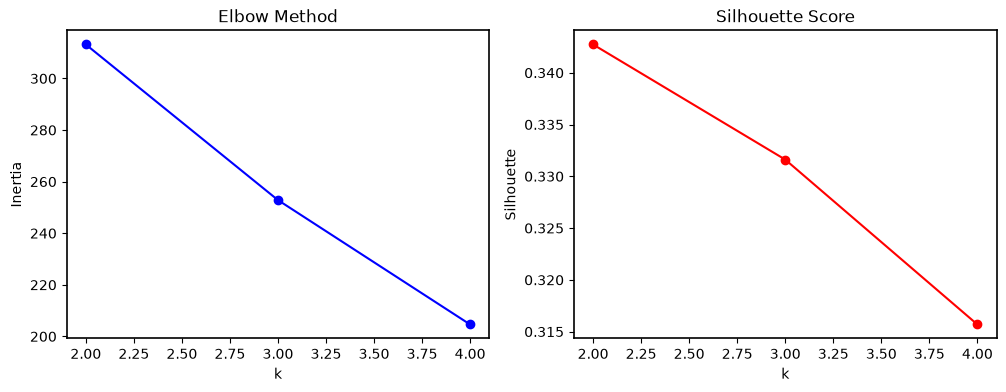

In [21]:

X = region_stats[[
    'Среднее значение', 'Коэфф. вариации', 'Среднегодовой темп роста',
    'Относит. изменение', 'Макс. падение', 'Доля отрицат. динамики'
]]



print(f'Размерность {X .shape}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.90, random_state=1)
X_pca = pca.fit_transform(X_scaled)

k_range = range(2,5)
kmean_score = []
inertias = []
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=1)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

    model_score_dict = {'model':'KMeans','k':k,'inertia':round(km.inertia_,2),'silhouette':sil_scores[-1]}
    kmean_score.append(model_score_dict)

# Графики
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(k_range, inertias, 'bo-')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(k_range, sil_scores, 'ro-')
ax2.set_xlabel('k')
ax2.set_ylabel('Silhouette')
ax2.set_title('Silhouette Score')

plt.show()



Размерность (79, 6)

Metrics for AgglomerativeClustering (n_clusters=2):
silhouette_score: 0.3172
calinski_harabasz_score: 28.8776
davies_bouldin_score: 1.3491
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=3):
silhouette_score: 0.3039
calinski_harabasz_score: 25.5539
davies_bouldin_score: 0.9390
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=4):
silhouette_score: 0.3228
calinski_harabasz_score: 28.0752
davies_bouldin_score: 0.9009
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=5):
silhouette_score: 0.2871
calinski_harabasz_score: 28.0417
davies_bouldin_score: 0.9693
----------------------------------------


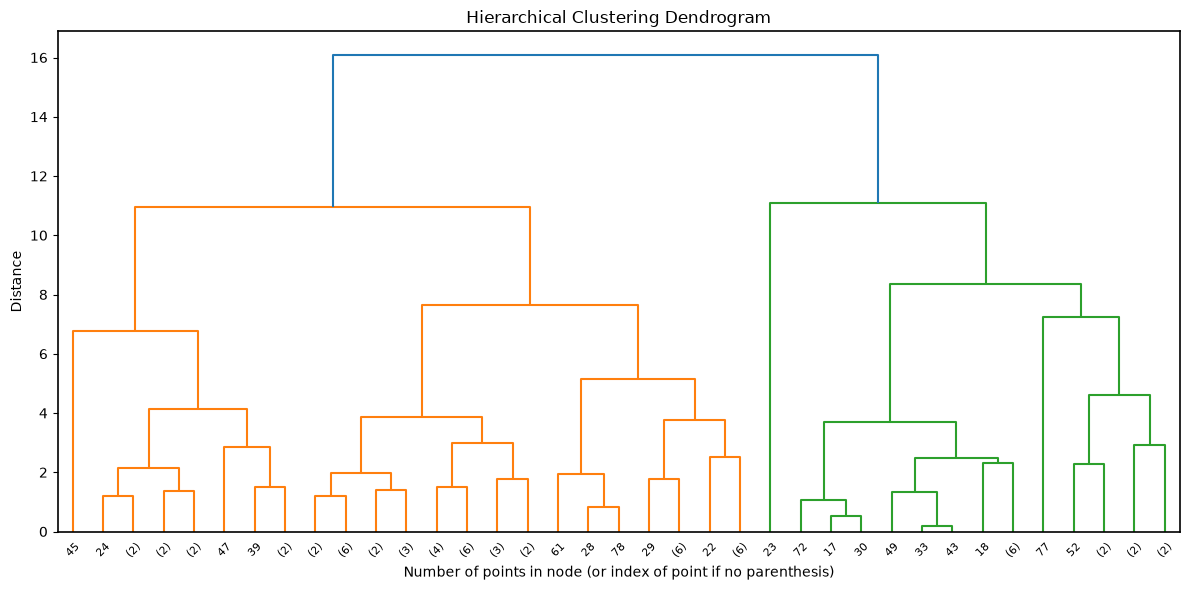


Анализ кластеров для k=2:

Кластер 1:
Регионы: Алтайский край, Амурская область, Архангельская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Воронежская область, Еврейская автономная область, Забайкальский край, Ивановская область, Кабардино-Балкарская Республика, Калинингpадская область, Калужская область, Кировская область, Костромская область, Краснодарский край, Курганская область, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Нижегородская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Бурятия, Республика Дагестан, Республика Ингушетия, Республика Калмыкия, Республика Карелия, Республика Марий Эл, Республика Мордовия, Республика Северная Осетия – Алания, Республика Татарстан, Республика Тыва, Республика Хакасия, Ростовская область, Рязанская область, Саратовск

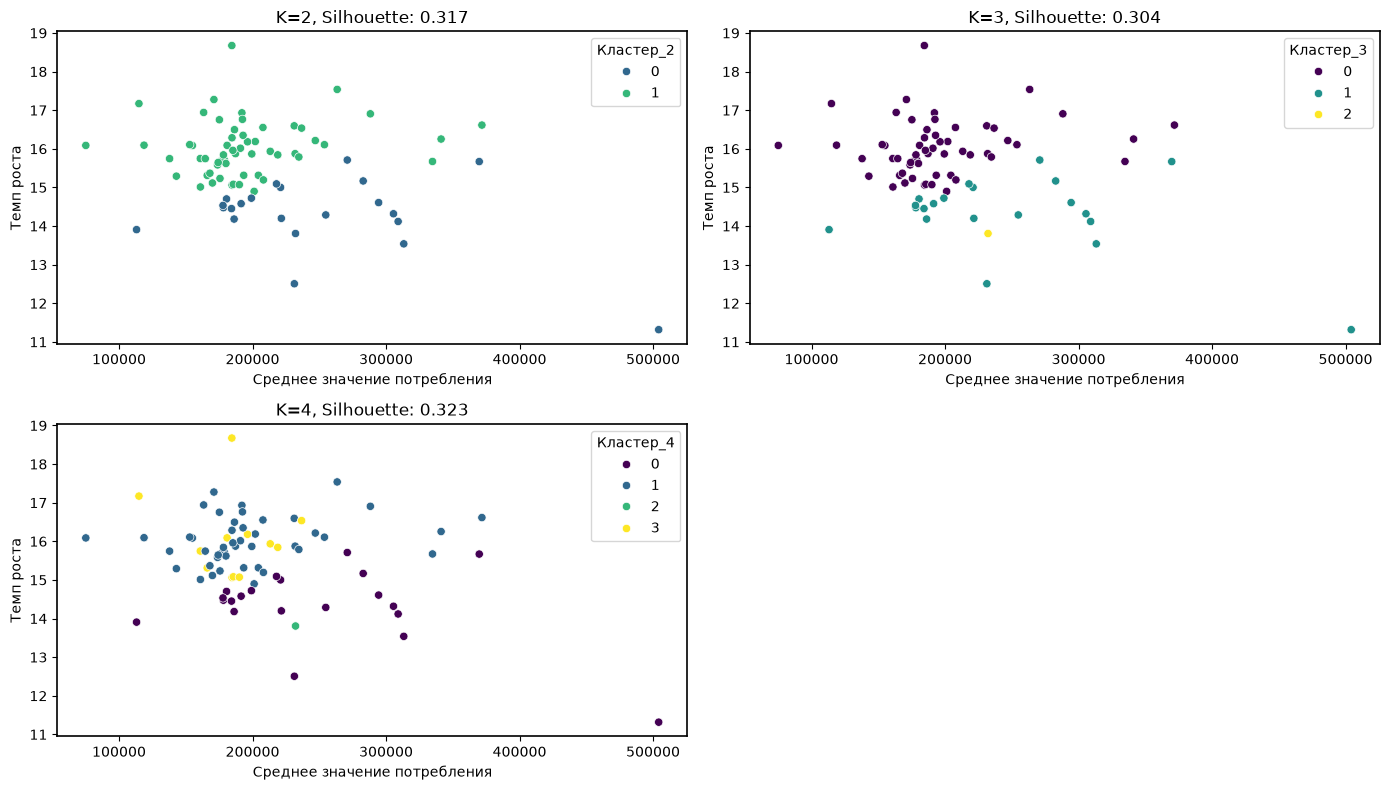

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram




# Метки предыдущих запусков не должны попадать в признаки.
feature_columns = [
    'Среднее значение', 'Коэфф. вариации', 'Среднегодовой темп роста',
    'Относит. изменение', 'Макс. падение', 'Доля отрицат. динамики'
]
X = region_stats[feature_columns]



print(f'Размерность {X .shape}')

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Иерархическая кластеризация
# Попробуем разные количества кластеров
results = {}
for n_clusters in [2, 3, 4, 5]:
    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage='ward'  # ward минимизирует внутрикластерную дисперсию
    )
    y_pred = model.fit_predict(X_scaled)
    
    silhouette = silhouette_score(X_scaled, y_pred)
    calinski = calinski_harabasz_score(X_scaled, y_pred)
    davies = davies_bouldin_score(X_scaled, y_pred)

    region_stats[f'Кластер_{n_clusters}'] = y_pred
    results[n_clusters] = {
        'score': silhouette,
        'calinski': calinski,
        'davies': davies
    }
    
    print(f"\nMetrics for AgglomerativeClustering (n_clusters={n_clusters}):")
    print(f"silhouette_score: {silhouette:.4f}")
    print(f"calinski_harabasz_score: {calinski:.4f}")
    print(f"davies_bouldin_score: {davies:.4f}")
    print("-" * 40)

# Построение дендрограммы
# Используем последнюю модель для визуализации
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None, linkage='ward')
model.fit(X_scaled)

# Создание матрицы связей для дендрограммы
def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count
    
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    
    dendrogram(linkage_matrix, **kwargs)

plt.figure(figsize=(12, 6))
plot_dendrogram(model, truncate_mode='level', p=5)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Number of points in node (or index of point if no parenthesis)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

# Анализ результатов кластеризации
for k in range(2, 5):
    print(f'\nАнализ кластеров для k={k}:')
    for cluster in region_stats[f'Кластер_{k}'].unique():
        cluster_data = region_stats[region_stats[f'Кластер_{k}'] == cluster]
        print(f'\nКластер {cluster}:')
        print(f'Регионы: {", ".join(cluster_data["region_name"])}')
        print(f'Среднее значение показателей:')
        print(cluster_data[['Среднее значение',
                          'Коэфф. вариации',
                          'Среднегодовой темп роста']].mean())

# Визуализация кластеров
plt.figure(figsize=(14, 8))
for k in range(2, 5):
    plt.subplot(2, 2, k-1)
    sns.scatterplot(x='Среднее значение',
                   y='Среднегодовой темп роста',
                   hue=f'Кластер_{k}',
                   data=region_stats,
                   palette='viridis')
    plt.title(f'K={k}, Silhouette: {results[k]["score"]:.3f}')
    plt.xlabel('Среднее значение потребления')
    plt.ylabel('Темп роста')

plt.tight_layout()
plt.show()

In [23]:
region_stats

,region_name,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики,Кластер_2,Кластер_3,Кластер_4,Кластер_5
0,Алтайский край,166038.220833,69.385702,15.311520,26.489394,-1.029618,0.043478,1,0,3,3
1,Амурская область,231900.291667,78.213754,15.874638,29.630089,3.508777,0.000000,1,0,1,0
2,Архангельская область,253850.283333,74.248898,16.106854,31.026354,3.716445,0.000000,1,0,1,0
3,Астраханская область,180520.654167,66.050339,14.702069,23.449782,0.861605,0.000000,0,1,0,4
4,Белгородская область,204367.341667,77.000531,15.314152,26.503303,5.376965,0.000000,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
74,Чувашская Республика,152949.233333,74.806523,16.108748,31.037993,2.255219,0.000000,1,0,1,0
75,Чукотский автономный округ,369809.887500,67.666672,15.669343,28.445933,-3.611779,0.043478,0,1,0,1
76,Ярославская область,199438.087500,74.676741,15.867348,29.587246,4.444213,0.000000,1,0,1,0
77,г. Москва,504230.937500,58.183507,11.316467,11.772441,0.281215,0.000000,0,1,0,1


In [24]:
model = AgglomerativeClustering(n_clusters=3)
region_stats['cluster'] = model.fit_predict(X_scaled)

# Списки регионов в каждом кластере.
for cluster, group in region_stats.groupby('cluster', sort=True):
    print(f'Кластер {cluster} — регионов: {len(group)}')
    for region in sorted(group['region_name']):
        print(f'  • {region}')
    print()

# Медианы исходных характеристик, без столбцов с метками кластеров.
median_features = [
    'Среднее значение', 'Коэфф. вариации', 'Среднегодовой темп роста',
    'Относит. изменение', 'Макс. падение', 'Доля отрицат. динамики'
]
cluster_medians = region_stats.groupby('cluster')[median_features].median()
print('Медианные характеристики кластеров:')
display(cluster_medians.round(3))


Кластер 0 — регионов: 57
  • Алтайский край
  • Амурская область
  • Архангельская область
  • Белгородская область
  • Брянская область
  • Владимирская область
  • Волгоградская область
  • Воронежская область
  • Еврейская автономная область
  • Забайкальский край
  • Ивановская область
  • Кабардино-Балкарская Республика
  • Калинингpадская область
  • Калужская область
  • Кировская область
  • Костромская область
  • Краснодарский край
  • Курганская область
  • Курская область
  • Ленинградская область
  • Липецкая область
  • Магаданская область
  • Московская область
  • Нижегородская область
  • Омская область
  • Оренбургская область
  • Орловская область
  • Пензенская область
  • Приморский край
  • Псковская область
  • Республика Адыгея
  • Республика Алтай
  • Республика Бурятия
  • Республика Дагестан
  • Республика Ингушетия
  • Республика Калмыкия
  • Республика Карелия
  • Республика Марий Эл
  • Республика Мордовия
  • Республика Северная Осетия – Алания
  • Респуб

,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики
cluster,,,,,,
0,185619.162,73.356,15.935,29.987,2.328,0.000
1,221578.492,67.053,14.475,22.404,0.281,0.000
2,232202.529,63.187,13.807,19.582,-53.292,0.043


## Этап 3. Выбор регионов для детального прогнозирования 
На основе кластеризации, выполненной на предыдущем этапе, выберите три региона для построения прогнозов. Эти регионы должны представлять разные типы динамики, выявленные при кластеризации.
Если в результате кластеризации получилось три или менее кластеров, возьмите по одному региону из каждого кластера. Если кластеров больше трёх, выберите три региона из разных кластеров, которые наилучшим образом отражают разнообразие динамических паттернов.
Учитывайте при выборе:

    • регион должен быть репрезентативным для своего кластера (его показатели близки к средним по кластеру);
    • либо, наоборот, регион может представлять крайний, но содержательно интересный случай внутри кластера (например, самый высокий темп роста или максимальную волатильность).
    
Свой выбор обоснуйте в отчёте: почему выбран именно этот регион, чем он интересен и почему он репрезентирует свой кластер. Для каждого выбранного региона приведите базовую статистику: среднее значение, минимальное и максимальное значение за период, оценку тренда (коэффициент наклона линейной регрессии).
Этап 4. Анализ выбранных регионов 

In [25]:
features = [
    'Среднее значение',
    'Коэфф. вариации',
    'Среднегодовой темп роста',
    'Относит. изменение',
    'Макс. падение',
    'Доля отрицат. динамики'
]

scaled = pd.DataFrame(
    StandardScaler().fit_transform(region_stats[features]),
    index=region_stats.index,
    columns=features
)

regions_list = []

for cluster, group in region_stats.groupby('cluster', sort=True):
    cluster_features = scaled.loc[group.index]
    center = cluster_features.mean()

    # Квадрат евклидова расстояния до центра кластера.
    distances = cluster_features.sub(center).pow(2).sum(axis=1)
    chosen_idx = distances.idxmin()
    chosen = region_stats.loc[chosen_idx, 'region_name']

    regions_list.append(chosen)
    print(f'Для кластера {cluster} выбран регион: {chosen}')

Для кластера 0 выбран регион: Курская область
Для кластера 1 выбран регион: Республика Коми
Для кластера 2 выбран регион: Красноярский край


Свой выбор обоснуйте в отчёте: почему выбран именно этот регион, чем он интересен и почему он репрезентирует свой кластер. Для каждого выбранного региона приведите базовую статистику: среднее значение, минимальное и максимальное значение за период, оценку тренда (коэффициент наклона линейной регрессии).

In [26]:
def selected_region_stats(df_long, regions_list):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in regions_list:
        series = time_series[region].dropna()

        # Максимальное значение
        max_value = series.max()
        # Минимальное значение
        min_value = series.min()
        # среднее
        mean_value = series.mean()


        # Если индекс — годы, а value — значения
        x = series.index.astype(int)          # годы как числа
        y = series           # значения

        slope, intercept = np.polyfit(x, y, deg=1)



        region_stats.append({
            'region_name': region,
            'Максимальное значение': max_value,
            'Минимальное значение': min_value,
            'Среднее значение': mean_value,
            'Наклон': slope,
        })
    region_stats = pd.DataFrame(region_stats)


    return region_stats

selected_region_stats(df_long, regions_list)

,region_name,Максимальное значение,Минимальное значение,Среднее значение,Наклон
0,Курская область,478025.8,15690.0,190928.508333,19575.576000
1,Республика Коми,594601.8,27557.3,254857.195833,22569.874130
2,Красноярский край,556338.0,28411.2,232202.529167,20211.433609


## Этап 4. Анализ выбранных регионов 
Для каждого из трёх выбранных регионов выполните полный анализ временного ряда. Постройте график исходного ряда. Оцените наличие тренда и циклических колебаний. Для выделения тренда используйте скользящее среднее или метод Ходрика — Прескотта (если сочтёте нужным). Проверьте каждый ряд на стационарность с помощью теста Дики — Фуллера и интерпретируйте результаты.
Поскольку данные годовые, внутригодовая сезонность отсутствует; сезонная декомпозиция к таким данным неприменима. В отчёте поясните, почему выделение сезонной компоненты для годовых данных не имеет смысла.
Постройте графики автокорреляционной функции (ACF) и частной автокорреляционной функции (PACF) для каждого ряда. Проанализируйте полученные графики: на основе их вида сформулируйте предположения о возможных порядках авторегрессионной (p) и скользящей средней (q) компонент для модели ARIMA. Зафиксируйте свои гипотезы в отчёте: в дальнейшем вы сможете сравнить их с результатами автоматического подбора параметров.
Сравните регионы между собой: у какого из них более выражен тренд, у какого выше волатильность, какой из них стационарен, а какой нет, как отличаются их ACF и PACF. Все выводы должны опираться на полученные графики и числовые значения.

Данные (первые 5 строк):
region_name  Алтайский край  Амурская область  Архангельская область  \
year                                                                   
2000                15751.1           20965.3                20638.3   
2001                21539.7           25983.5                29600.6   
2002                28855.5           33058.9                37678.0   
2003                35772.7           39258.2                46001.5   
2004                44268.9           50483.3                58204.3   

region_name  Астраханская область  Белгородская область  Брянская область  \
year                                                                        
2000                      17043.6               19420.9           13394.1   
2001                      22997.3               22799.1           18433.1   
2002                      29804.0               26386.5           25521.0   
2003                      35409.4               31254.0           31086.7   
2004    

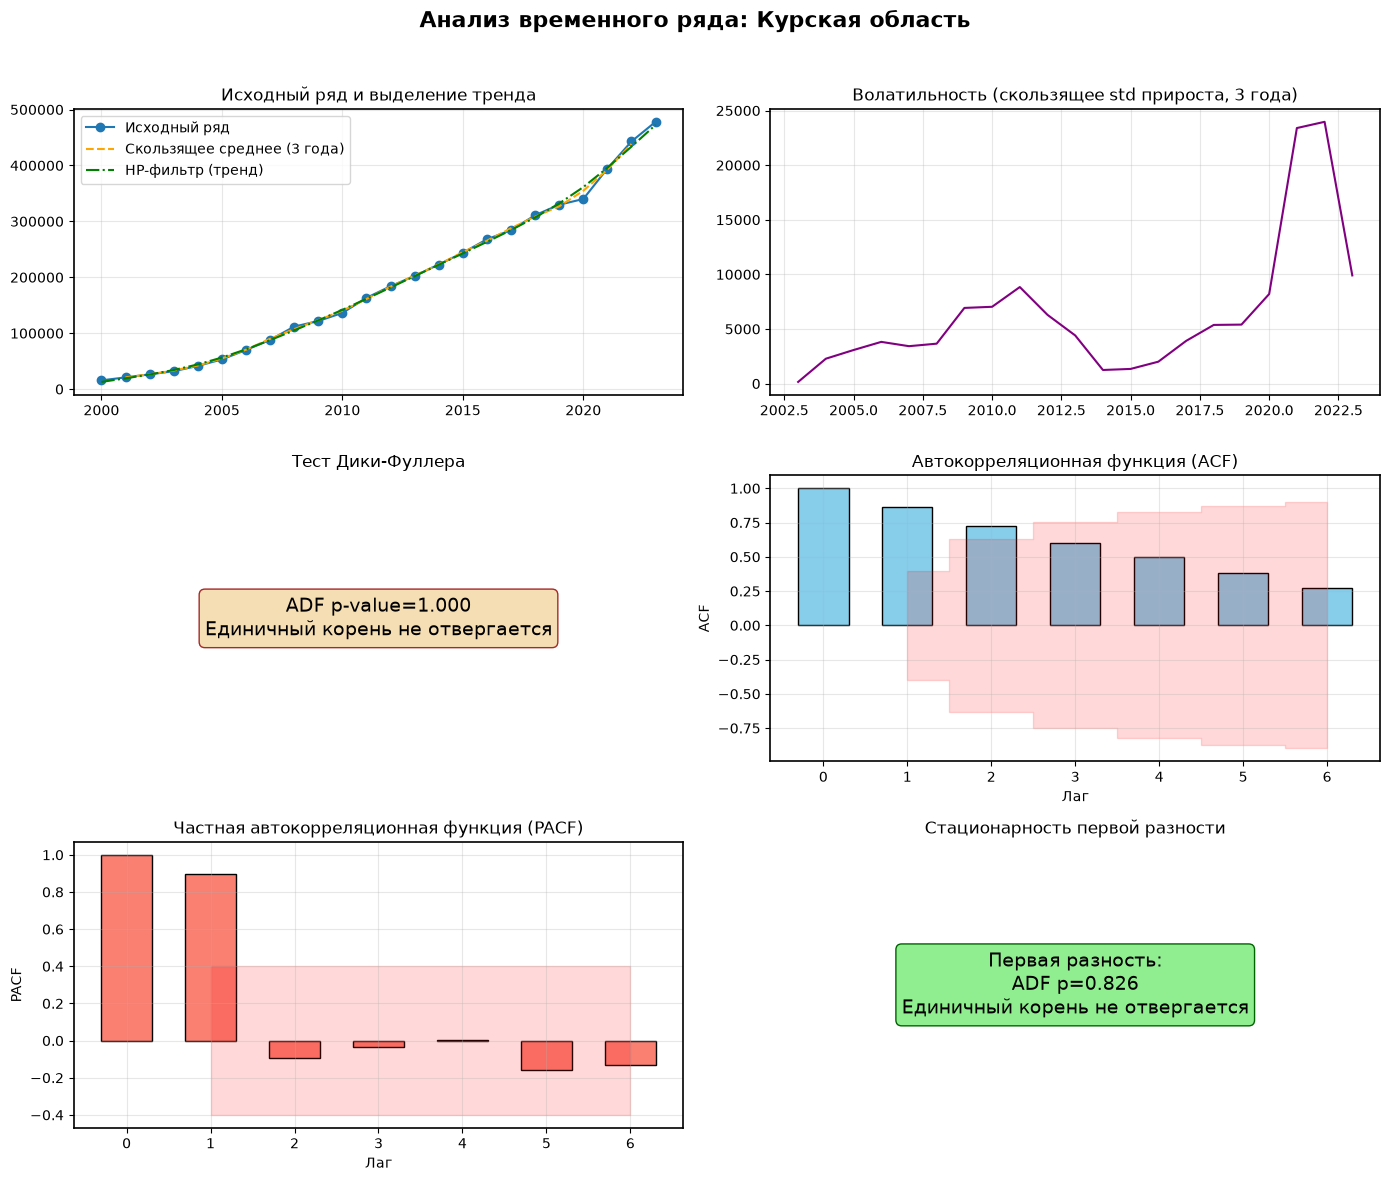

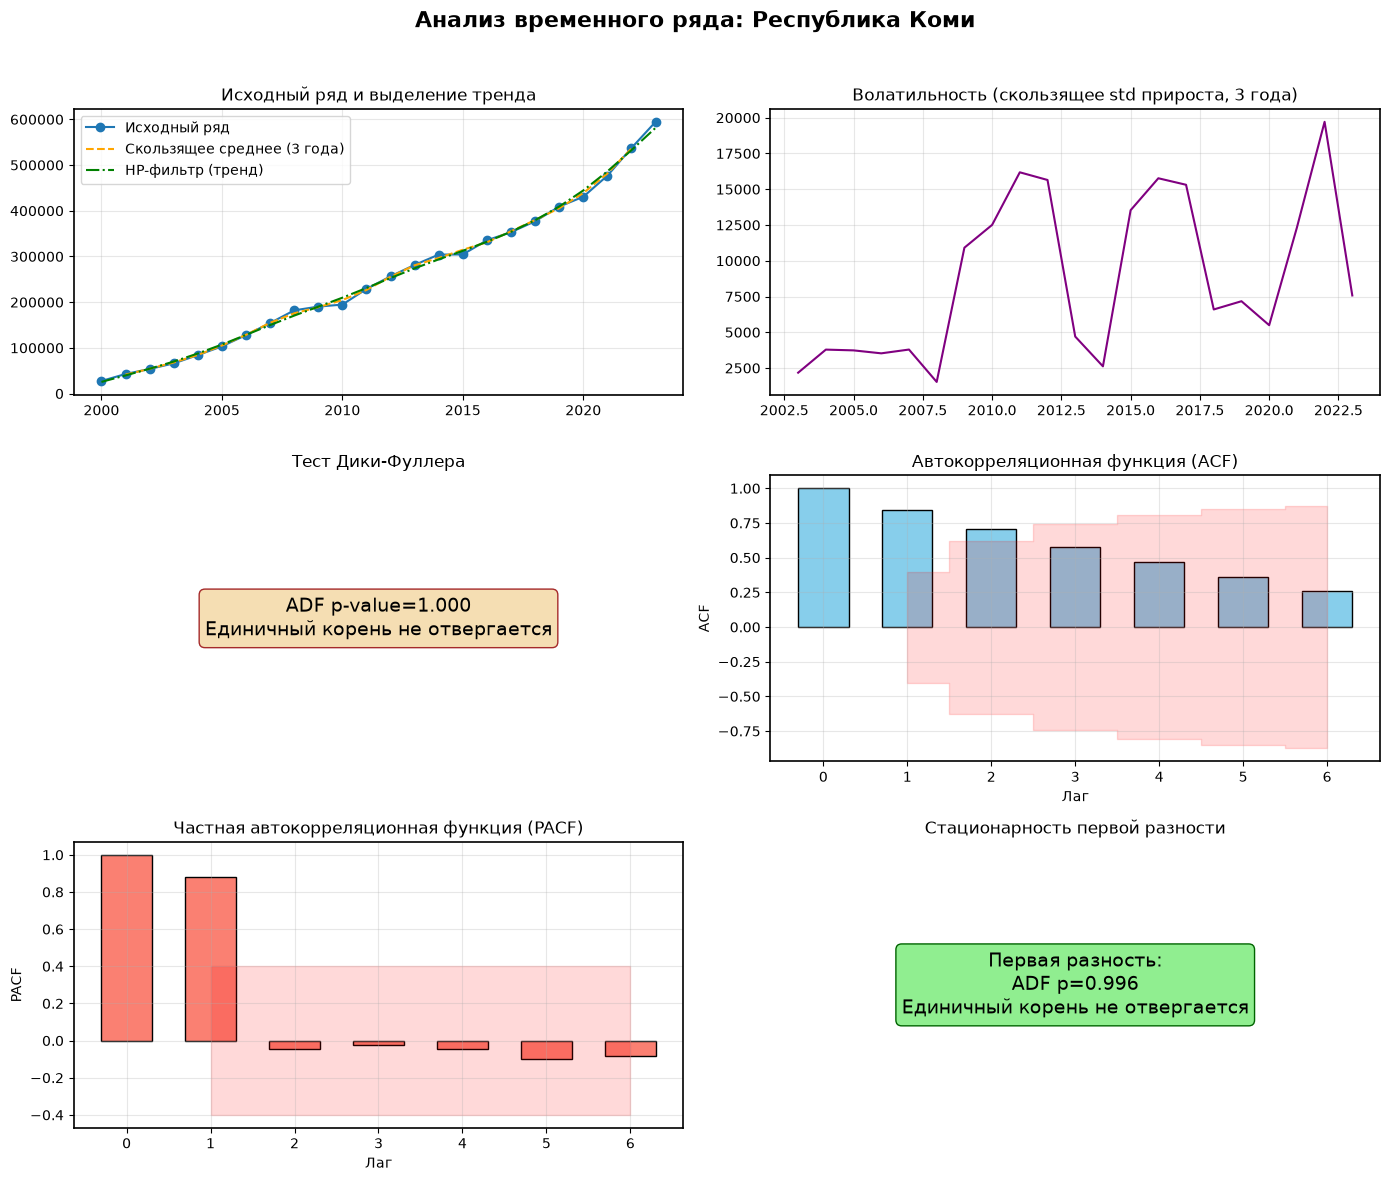

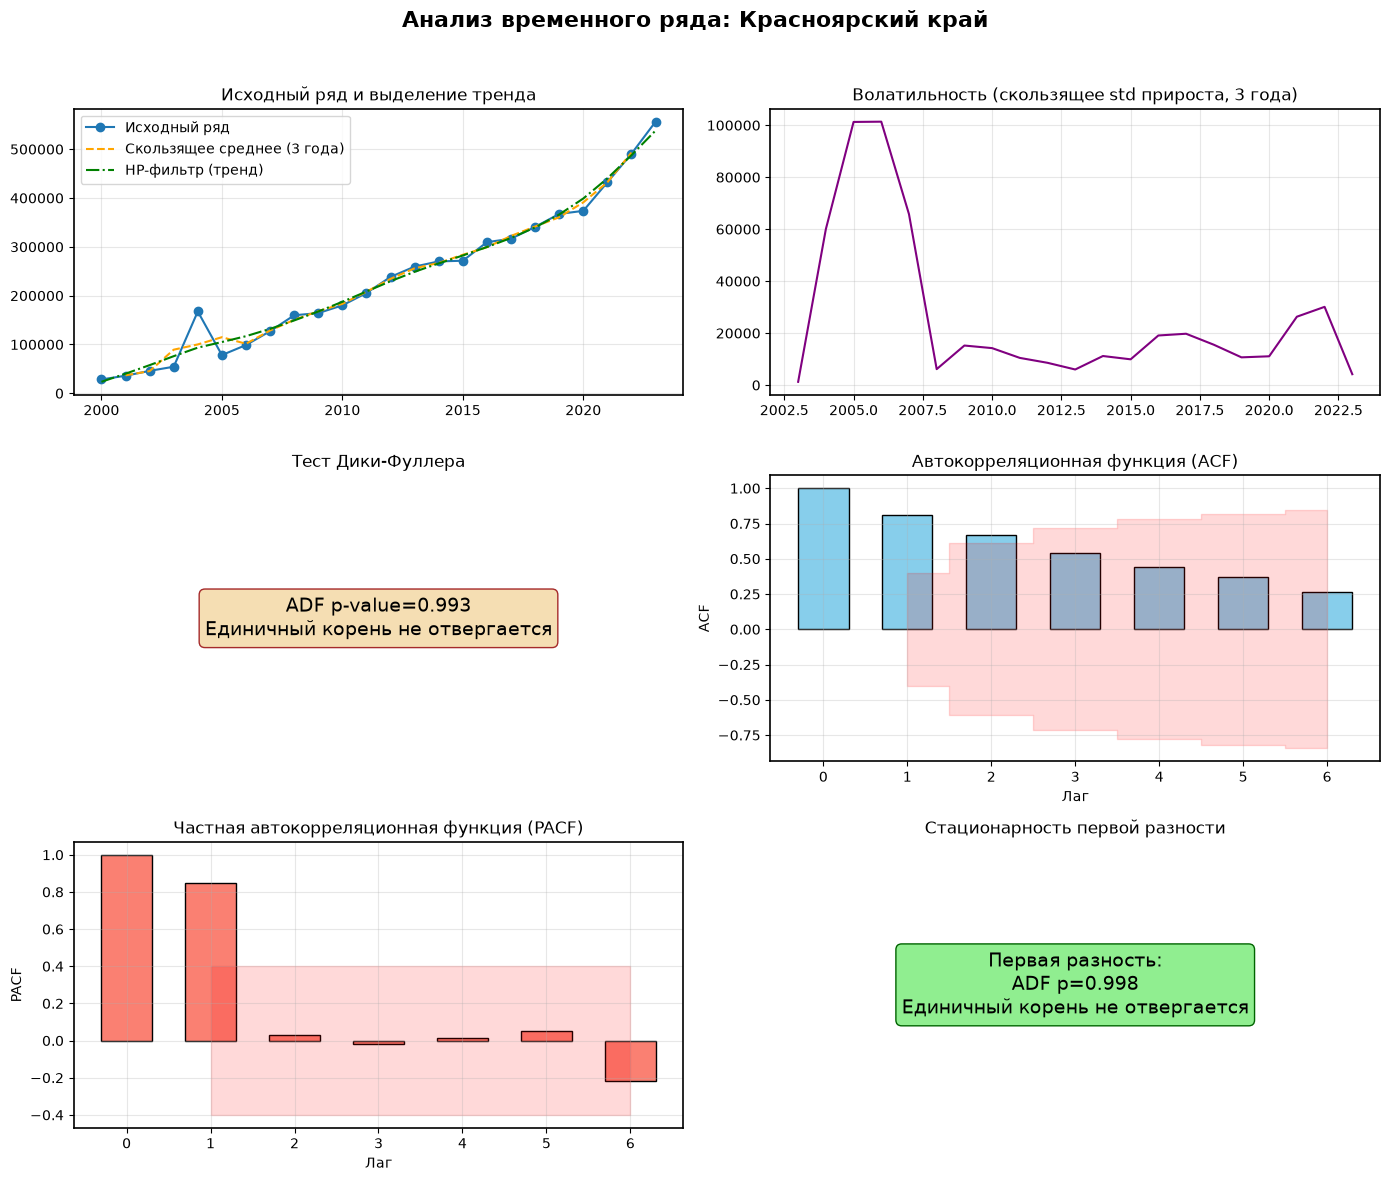

Сводная таблица гипотез ARIMA и характеристик:
           Регион  ADF_pvalue  Стационарен  Гипотеза_d  Гипотеза_p  Гипотеза_q  Волатильность_std  Тренд_HP_slope
  Курская область       1.000        False           1           1           1          12479.748       19575.576
  Республика Коми       1.000        False           1           1           1          14854.637       22569.874
Красноярский край       0.993        False           1           0           0          35507.514       20211.434


In [27]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import acf, pacf
import statsmodels.api as sm
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["axes.linewidth"] = 1.2

# ---------------------------------------------------------
# 1. Ваши данные (можно заменить на загрузку из файла)
# ---------------------------------------------------------
# Создаем отдельные временные ряды
df_regions = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()


regions = {name: df_regions[name].copy() for name in regions_list}

print("Данные (первые 5 строк):")
print(df_regions.head(), "\n")

# ---------------------------------------------------------
# 2. Вспомогательные функции
# ---------------------------------------------------------

def hp_filter(series, lamb=6.25):
    """Фильтр Ходрика–Прескотта для годовых данных."""
    cycle, trend = sm.tsa.filters.hpfilter(series.values, lamb=lamb)
    return pd.Series(trend, index=series.index)


def safe_nlags(series, max_lags=6):
    """
    Максимально допустимое число лагов для pacf: nlags < n // 2.
    Для слишком короткого ряда выдаёт понятную ошибку.
    """
    n = series.dropna().shape[0]
    if n < 4:
        raise ValueError('Для ACF/PACF нужно как минимум 4 наблюдения.')
    return min(max_lags, n // 2 - 1)


def adf_test(series):
    """ADF-тест с подавлением FutureWarning (result_object=True)."""
    result = adfuller(series.dropna(), autolag='AIC',
                      regression='c', result_object=True)
    p_value = result.pvalue
    is_stationary = p_value < 0.05
    return p_value, is_stationary


def get_acf_pacf(series, nlags=None):
    """
    ACF/PACF с автоматическим выбором безопасного nlags.
    Для statsmodels 0.15 используем result_object=True.
    Доверительные интервалы confint имеют форму (nlags+1, 2).
    """
    nlags = safe_nlags(series, 6 if nlags is None else nlags)
    acf_res = acf(series.dropna(), nlags=nlags, alpha=0.05,
                  fft=False, result_object=True)
    pacf_res = pacf(series.dropna(), nlags=nlags, alpha=0.05,
                    result_object=True)
    return acf_res.acf, acf_res.confint, pacf_res.pacf, pacf_res.confint


def _conf_bounds(conf, values):
    """Переносим интервалы вокруг оценки корреляции к нулю для графика."""
    centered = np.asarray(conf) - np.asarray(values)[:, None]
    return centered[:, 0], centered[:, 1]


def plot_region_analysis(name, s):
    fig, axs = plt.subplots(3, 2, figsize=(14, 12))
    fig.suptitle(f"Анализ временного ряда: {name}", fontsize=16, fontweight="bold")

    # 1) Исходный ряд + тренды
    ma = s.rolling(window=3, center=True).mean()
    hp_trend = hp_filter(s)
    ax = axs[0, 0]
    ax.plot(s, label='Исходный ряд', marker='o', linewidth=1.5)
    ax.plot(ma, label='Скользящее среднее (3 года)',
            linestyle='--', color='orange', linewidth=1.5)
    ax.plot(hp_trend, label='HP‑фильтр (тренд)',
            linestyle='-.', color='green', linewidth=1.5)
    ax.set_title('Исходный ряд и выделение тренда')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

    # 2) Волатильность (std прироста в скользящем окне)
    vol = s.diff().rolling(window=3).std()
    ax = axs[0, 1]
    ax.plot(vol, color='purple', linewidth=1.5)
    ax.set_title('Волатильность (скользящее std прироста, 3 года)')
    ax.grid(True, alpha=0.3)

    # 3) Тест Дики‑Фуллера
    p_val, is_stat = adf_test(s)
    txt = f"ADF p-value={p_val:.3f}\n{'Единичный корень отвергается' if is_stat else 'Единичный корень не отвергается'}"
    ax = axs[1, 0]
    ax.text(0.5, 0.5, txt, ha='center', va='center', fontsize=14,
            bbox=dict(boxstyle="round", facecolor="wheat", edgecolor="brown"))
    ax.axis('off')
    ax.set_title('Тест Дики‑Фуллера')

    # безопасное число лагов для ACF/PACF
    nlags = safe_nlags(s, max_lags=6)

    # 4) ACF
    acf_vals, conf_acf, _, _ = get_acf_pacf(s, nlags=nlags)
    lags = np.arange(len(acf_vals))
    low_acf, up_acf = _conf_bounds(conf_acf, acf_vals)
    ax = axs[1, 1]
    ax.bar(lags, acf_vals, width=0.6, color='skyblue', edgecolor='black')
    ax.fill_between(lags[1:], low_acf[1:], up_acf[1:],
                    color='red', alpha=0.15, step='mid')
    ax.set_title('Автокорреляционная функция (ACF)')
    ax.set_xlabel('Лаг')
    ax.set_ylabel('ACF')
    ax.grid(True, alpha=0.3)

    # 5) PACF
    _, _, pacf_vals, conf_pacf = get_acf_pacf(s, nlags=nlags)
    low_pacf, up_pacf = _conf_bounds(conf_pacf, pacf_vals)
    ax = axs[2, 0]
    ax.bar(lags, pacf_vals, width=0.6, color='salmon', edgecolor='black')
    ax.fill_between(lags[1:], low_pacf[1:], up_pacf[1:],
                    color='red', alpha=0.15, step='mid')
    ax.set_title('Частная автокорреляционная функция (PACF)')
    ax.set_xlabel('Лаг')
    ax.set_ylabel('PACF')
    ax.grid(True, alpha=0.3)

    # 6) Стационарность первой разности
    diff = s.diff().dropna()
    p_val_diff, is_stat_diff = adf_test(diff)
    txt_diff = (f"Первая разность:\nADF p={p_val_diff:.3f}\n"
                f"{'Единичный корень отвергается' if is_stat_diff else 'Единичный корень не отвергается'}")
    ax = axs[2, 1]
    ax.text(0.5, 0.5, txt_diff, ha='center', va='center', fontsize=14,
            bbox=dict(boxstyle="round", facecolor="lightgreen", edgecolor="darkgreen"))
    ax.axis('off')
    ax.set_title('Стационарность первой разности')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------
# 3. Анализ по регионам
# ---------------------------------------------------------
for name, s in regions.items():
    plot_region_analysis(name, s)

# ---------------------------------------------------------
# 4. Сводная таблица гипотез для ARIMA
# ---------------------------------------------------------
summary = []
for name, s in regions.items():
    p_val, is_stat = adf_test(s)

    d_hyp = 1 if p_val >= 0.05 else 0
    diagnostic_series = s.diff().dropna() if d_hyp else s
    nlags = safe_nlags(diagnostic_series, max_lags=6)
    acf_vals, conf_acf, pacf_vals, conf_pacf = get_acf_pacf(
        diagnostic_series, nlags=nlags
    )

    # Предварительные кандидаты по значимым лагам ряда после разности.
    # Это ориентир для перебора ARIMA, а не автоматический выбор порядка.
    acf_significant = (conf_acf[1:, 0] > 0) | (conf_acf[1:, 1] < 0)
    pacf_significant = (conf_pacf[1:, 0] > 0) | (conf_pacf[1:, 1] < 0)
    p_hyp = int(np.flatnonzero(pacf_significant[:3])[-1] + 1) if pacf_significant[:3].any() else 0
    q_hyp = int(np.flatnonzero(acf_significant[:3])[-1] + 1) if acf_significant[:3].any() else 0

    hp_trend = hp_filter(s)
    trend_slope = np.polyfit(range(len(hp_trend)), hp_trend.values, 1)[0]

    summary.append({
        "Регион": name,
        "ADF_pvalue": round(p_val, 3),
        "Стационарен": is_stat,
        "Гипотеза_d": d_hyp,
        "Гипотеза_p": p_hyp,
        "Гипотеза_q": q_hyp,
        "Волатильность_std": round(s.diff().std(), 3),
        "Тренд_HP_slope": round(trend_slope, 3),
    })

summary_df = pd.DataFrame(summary)
print("Сводная таблица гипотез ARIMA и характеристик:")
print(summary_df.to_string(index=False))


## Этап 5. Прогнозирование (12 баллов)

### Подготовка данных
- Разделить данные на обучающую и тестовую выборки. Обучающая — не менее 70% данных.
- Горизонт прогноза выбрать самостоятельно, но он должен быть одинаковым для всех регионов.

### Модели
Реализовать три модели:
1. **NaiveForecaster** (`strategy="last"`) из `sktime` — бейзлайн.
2. **Модель экспоненциального сглаживания с трендом (Holt)** — например, через `statsmodels.tsa.holtwinters.ExponentialSmoothing` (без сезонности, так как данные годовые).
3. **ARIMA** — через `statsmodels.tsa.arima.model.ARIMA`. Параметры можно подбирать вручную на основе ACF/PACF или автоматически (например, `auto_arima` из `pmdarima`).


=== Разбиение train/test ===
Курская область: train 17 точек (2000–2016), test 7 точек (2017–2023)
Республика Коми: train 17 точек (2000–2016), test 7 точек (2017–2023)
Красноярский край: train 17 точек (2000–2016), test 7 точек (2017–2023)

=== Оценка моделей на тестовой выборке ===
           Регион Модель     Факт    Прогноз          RMSE    MAPE,%
  Курская область  Naive 284312.4 267964.800 120619.469628 24.999716
  Курская область   Holt 284312.4 290648.300  26036.559899  4.741445
  Курская область  ARIMA 284312.4 279267.977 111361.242152 21.836085
  Республика Коми  Naive 353130.6 335385.500 143677.780034 23.859630
  Республика Коми   Holt 353130.6 349281.499  63431.669424  8.926113
  Республика Коми  ARIMA 353130.6 363762.306 121296.382698 18.277630
Красноярский край  Naive 316572.5 309547.200 129407.646815 21.992100
Красноярский край   Holt 316572.5 310404.822  70569.433001 10.706660
Красноярский край  ARIMA 316572.5 302360.438 135120.263089 23.803211

=== Лучшая модель по каж

/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sk


=== Устойчивость прогноза (expanding window) ===
           Регион Модель  Итерация  Train_n    Прогноз     Факт  |Ошибка|  MAPE_1шаг,%
  Курская область   Holt        17       17 290648.300 284312.4  6335.900     2.228499
  Курская область   Holt        18       18 303614.563 310981.0  7366.437     2.368774
  Курская область   Holt        19       19 333348.198 329726.9  3621.298     1.098272
  Курская область   Holt        20       20 350665.752 339993.3 10672.452     3.139018
  Курская область   Holt        21       21 355940.947 394356.6 38415.653     9.741349
  Курская область   Holt        22       22 407448.830 442957.9 35509.070     8.016353
  Курская область   Holt        23       23 484571.749 478025.8  6545.949     1.369372
  Республика Коми   Holt        17       17 349281.499 353130.6  3849.101     1.089993
  Республика Коми   Holt        18       18 369392.431 377000.8  7608.369     2.018131
  Республика Коми   Holt        19       19 391630.571 409038.8 17408.229     4.

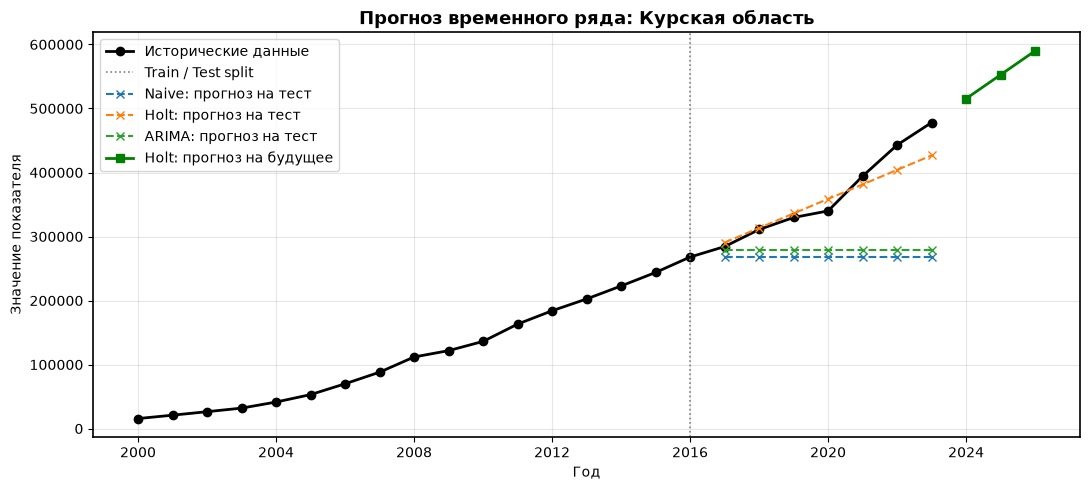

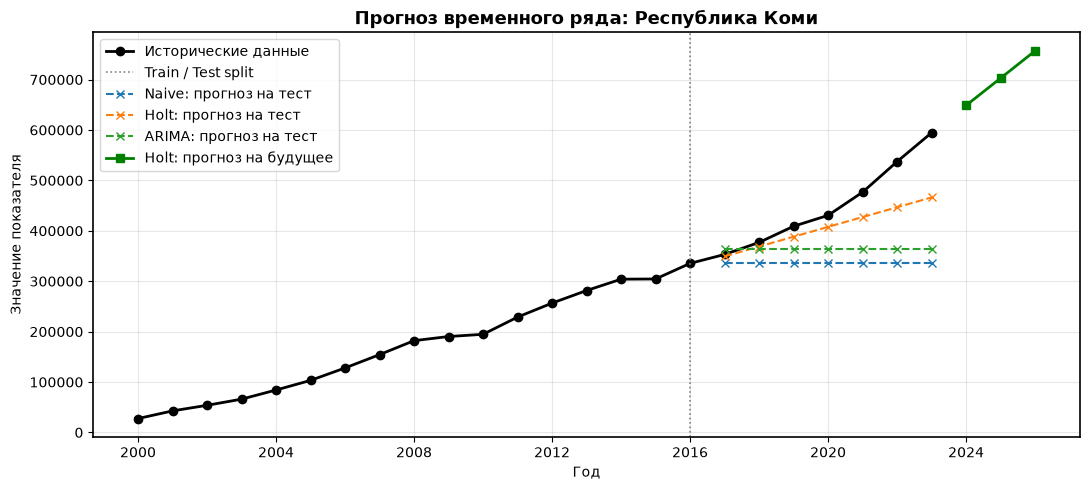

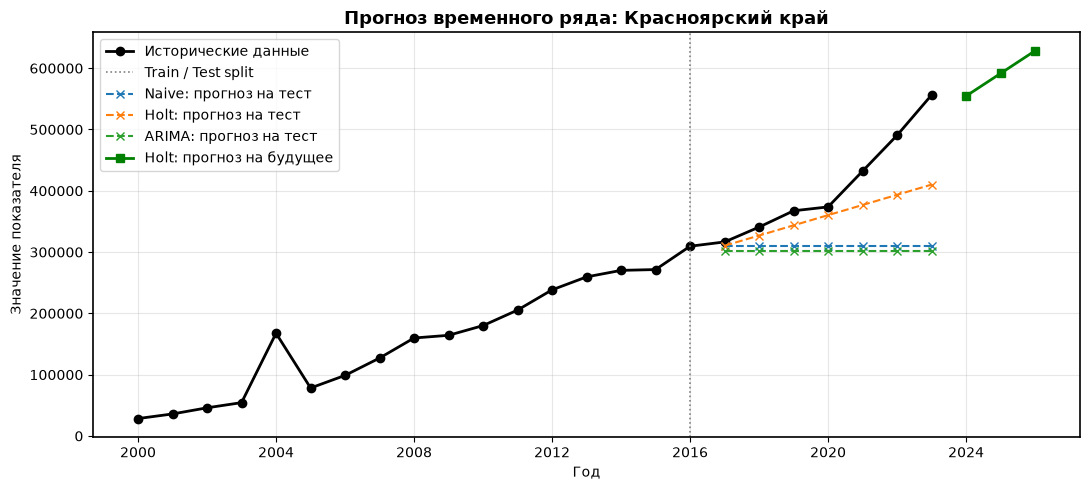


=== ВЫВОДЫ ===
Курская область: лучшая модель — Holt (RMSE=26036.560, MAPE=4.74%). Статистическая модель превзошла бейзлайн.
Республика Коми: лучшая модель — Holt (RMSE=63431.669, MAPE=8.93%). Статистическая модель превзошла бейзлайн.
Красноярский край: лучшая модель — Holt (RMSE=70569.433, MAPE=10.71%). Статистическая модель превзошла бейзлайн.


In [28]:
# =========================================================
# Импорты
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# --- sktime (бейзлайн) ---
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.base import ForecastingHorizon

# --- statsmodels ---
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA


# =========================================================
# 1. Данные
# =========================================================
# Преобразуем именно годы, а не числа наносекунд от начала Unix-эпохи.
forecast_regions = {}
for name, series in regions.items():
    series = series.copy().sort_index()
    if not isinstance(series.index, pd.DatetimeIndex):
        series.index = pd.to_datetime(series.index.astype(str), format="%Y")
    if series.index.has_duplicates:
        raise ValueError(f"{name}: повторяющиеся годы в индексе")
    series = series.asfreq("YS").astype(float)
    if not np.isfinite(series.to_numpy()).all():
        raise ValueError(f"{name}: ряд содержит пропуски или бесконечные значения")
    forecast_regions[name] = series
if not forecast_regions:
    raise ValueError("Нет выбранных регионов: выполните предыдущие ячейки")


# =========================================================
# 2. Train/test split + горизонт
# =========================================================
# Для 24 наблюдений: 17 лет в train, 7 лет в test.
# Общий горизонт сохраняет не менее 70% каждого ряда для обучения.
HORIZON = min(len(series) - int(np.ceil(0.7 * len(series)))
              for series in forecast_regions.values())
if HORIZON < 1:
    raise ValueError("Недостаточно данных для train/test")
FUTURE_HORIZON = 3

splits = {}
print("=== Разбиение train/test ===")
for name, s in forecast_regions.items():
    n = len(s)
    n_train = n - HORIZON
    train = s.iloc[:n_train].asfreq("YS")
    test  = s.iloc[n_train:].asfreq("YS")
    splits[name] = (train, test)
    print(f"{name}: train {len(train)} точек "
          f"({train.index[0].year}–{train.index[-1].year}), "
          f"test {len(test)} точек ({test.index[0].year}–{test.index[-1].year})")


# =========================================================
# 3. Три модели
# =========================================================
def forecast_naive(train, horizon):
    """NaiveForecaster(strategy='last') — бейзлайн."""
    forecaster = NaiveForecaster(strategy="last")
    forecaster.set_config(remember_data=False)
    forecaster.fit(train)
    fh = ForecastingHorizon(np.arange(1, horizon + 1), is_relative=True)
    return forecaster.predict(fh)


def forecast_holt(train, horizon):
    """Holt с аддитивным трендом, без сезонности."""
    model = ExponentialSmoothing(
        train, trend="add", seasonal=None, initialization_method="estimated"
    ).fit(optimized=True)
    return model.forecast(horizon)


def forecast_arima(train, horizon, order=(0, 1, 1)):
    """Фиксированный кандидат ARIMA; тестовые значения в обучение не входят."""
    model = ARIMA(train, order=order).fit()
    return model.forecast(horizon)


MODELS = {
    "Naive": forecast_naive,
    "Holt":  forecast_holt,
    "ARIMA": lambda tr, h: forecast_arima(tr, h, order=(0, 1, 1)),
}


# =========================================================
# 4. Метрики
# =========================================================
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if not mask.any():
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


# =========================================================
# 5. Оценка на фиксированном train/test
# =========================================================
results = []
forecasts_test = {}   # для графиков

for name, (train, test) in splits.items():
    forecasts_test[name] = {}
    for mname, func in MODELS.items():
        try:
            pred = np.asarray(func(train, HORIZON), dtype=float)
            if pred.shape != (len(test),) or not np.isfinite(pred).all():
                raise ValueError("Прогноз должен содержать конечные значения для всех лет test")
            forecasts_test[name][mname] = pred
            results.append({
                "Регион":  name,
                "Модель":  mname,
                "Факт":    round(float(test.iloc[0]), 3) if len(test) else np.nan,
                "Прогноз": round(float(pred[0]), 3) if len(pred) else np.nan,
                "RMSE":    rmse(test.values, pred),
                "MAPE,%":  mape(test.values, pred),
            })
        except Exception as e:
            print(f"[{name}/{mname}] ошибка: {e}")

results_df = pd.DataFrame(results, columns=[
    "Регион", "Модель", "Факт", "Прогноз", "RMSE", "MAPE,%"
])
missing_regions = set(forecast_regions) - set(results_df["Регион"])
if missing_regions:
    raise RuntimeError(f"Не удалось оценить ни одну модель: {sorted(missing_regions)}")
print("\n=== Оценка моделей на тестовой выборке ===")
print(results_df.to_string(index=False))


# =========================================================
# 6. Устойчивость: Expanding window для лучшей модели региона
# =========================================================
best_per_region = (results_df.dropna(subset=["RMSE"])
                   .sort_values("RMSE")
                   .groupby("Регион", as_index=False).first())

print("\n=== Лучшая модель по каждому региону (по RMSE) ===")
print(best_per_region[["Регион", "Модель", "RMSE", "MAPE,%"]].to_string(index=False))

stability_rows = []
for name, s in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    func = MODELS[best_name]

    # Expanding window: train на первых k точках, прогноз на (k+1)-ю
    for k in range(len(splits[name][0]), len(s)):
        train_k = s.iloc[:k].asfreq("YS")
        true_next = float(s.iloc[k])
        try:
            pred_val = float(np.asarray(func(train_k, 1), dtype=float)[0])
            stability_rows.append({
                "Регион": name,
                "Модель": best_name,
                "Итерация": k,
                "Train_n": k,
                "Прогноз": round(pred_val, 3),
                "Факт":   round(true_next, 3),
                "|Ошибка|": round(abs(pred_val - true_next), 3),
                "MAPE_1шаг,%": mape([true_next], [pred_val]),
            })
        except Exception as e:
            print(f"[{name}/{best_name}/iter{k}] ошибка: {e}")

stab_df = pd.DataFrame(stability_rows)
print("\n=== Устойчивость прогноза (expanding window) ===")
print(stab_df.to_string(index=False))

# Сводка: фикс. train/test vs средняя по expanding window
print("\n=== Сравнение фикс. test и expanding window ===")
cmp_rows = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    fixed_mape = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == best_name)]["MAPE,%"].iloc[0]
    win = stab_df[stab_df["Регион"] == name]
    exp_mape = round(win["MAPE_1шаг,%"].mean(), 2) if len(win) else np.nan
    cmp_rows.append({
        "Регион": name, "Модель": best_name,
        "MAPE_fixed,%": fixed_mape,
        "MAPE_expanding(avg),%": exp_mape,
        "Δ, п.п.": round(exp_mape - fixed_mape, 2) if pd.notna(exp_mape) else np.nan,
    })
cmp_df = pd.DataFrame(cmp_rows)
print(cmp_df.to_string(index=False))


# =========================================================
# 7. Визуализация: история + прогноз на тест + прогноз в будущее
# =========================================================
for name, s in forecast_regions.items():
    train, test = splits[name]
    fig, ax = plt.subplots(figsize=(11, 5))

    # 7.1 История
    ax.plot(s.index, s.values, marker="o", lw=2,
            color="black", label="Исторические данные")

    # 7.2 Разделение train / test
    ax.axvline(x=train.index[-1], color="gray", ls=":", lw=1.2,
               label="Train / Test split")

    # 7.3 Прогноз на тестовую выборку (все 3 модели)
    for mname in MODELS:
        pred_arr = forecasts_test[name].get(mname)
        if pred_arr is None or len(test) == 0:
            continue
        pred_ser = pd.Series(pred_arr[:len(test)], index=test.index)
        ax.plot(pred_ser.index, pred_ser.values, marker="x", ls="--",
                label=f"{mname}: прогноз на тест")

    # 7.4 Прогноз в будущее — от лучшей модели, обученной на полном ряду
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    try:
        future_pred = np.asarray(
            MODELS[best_name](s.asfreq("YS"), FUTURE_HORIZON), dtype=float)
        future_idx = pd.date_range(
            s.index[-1] + pd.DateOffset(years=1),
            periods=FUTURE_HORIZON, freq="YS")
        ax.plot(future_idx, future_pred, marker="s", ls="-", lw=2,
                color="green", label=f"{best_name}: прогноз на будущее")
    except Exception as e:
        print(f"[{name}] future forecast error: {e}")

    ax.set_title(f"Прогноз временного ряда: {name}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Год")
    ax.set_ylabel("Значение показателя")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


# =========================================================
# 8. Выводы
# =========================================================
print("\n=== ВЫВОДЫ ===")
for name in forecast_regions:
    row = results_df[results_df["Регион"] == name].dropna(subset=["RMSE"])
    row = row.sort_values("RMSE")
    best = row.iloc[0]
    naive_rmse = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == "Naive")]["RMSE"].iloc[0]
    better_than_naive = best["Модель"] != "Naive" and best["RMSE"] < naive_rmse
    msg = (f"{name}: лучшая модель — {best['Модель']} "
           f"(RMSE={best['RMSE']:.3f}, MAPE={best['MAPE,%']:.2f}%). ")
    if better_than_naive:
        msg += "Статистическая модель превзошла бейзлайн."
    else:
        msg += ("На выбранной тестовой выборке бейзлайн Naive не превзойдён.")
    print(msg)

## Этап 6. Анализ ошибок (5 баллов)

Для лучшей модели каждого региона:
1. Найти точки с наибольшими ошибками (топ‑5 по абсолютной ошибке).
2. Представить результаты в виде таблицы или графика.
3. Сопоставить эти годы с известными экономическими событиями (кризис 2008, падение цен на нефть 2014, пандемия 2020, санкционное давление 2022 и т.п.).
4. Сформулировать гипотезы, почему модель ошиблась в эти периоды (например, структурные сдвиги, резкие изменения тренда, внешние шоки).

## Этап 6. Анализ ошибок

Для лучшей по RMSE модели каждого региона используем сохранённый прогноз на тестовые годы 2017–2023. Ошибка = факт − прогноз: положительная ошибка означает недооценку показателя. Топ‑5 определяется по абсолютной ошибке отдельно внутри каждого региона.

В 2008–2009 годах мировой финансовый кризис сопровождался в России падением цен на нефть и оттоком капитала ([МВФ, 2009](https://www.imf.org/en/news/articles/2015/09/28/04/53/pn0999)). В 2020 году пандемия и ограничения экономической активности повлияли на потребление ([Всемирный банк, 2020](https://blogs.worldbank.org/en/europeandcentralasia/under-shadow-pandemic-reflections-russias-response)).

2008 год находится в обучающей выборке, поэтому его нельзя включать в топ ошибок тестового прогноза. Для сопоставления событий дополнительно строим однолетние ретроспективные прогнозы на 2008, 2009 и 2020 годы: при каждом обучении используются только предшествующие годы. Тип модели берётся из этапа 5, то есть выбран по более позднему тесту; это историческая диагностика, а не независимая проверка выбора модели. Её ошибки отделены от многолетнего тестового прогноза.


Топ‑5 ошибок лучшей модели каждого региона на тестовой выборке:


,Регион,Модель,Год,Факт,Прогноз,Ошибка,Абсолютная ошибка,"Ошибка,%",Место
0,Курская область,Holt,2023,478025.8,426749.30,51276.50,51276.50,10.73,1
1,Курская область,Holt,2022,442957.9,404065.80,38892.10,38892.10,8.78,2
2,Курская область,Holt,2020,339993.3,358698.80,-18705.50,18705.50,5.50,3
3,Курская область,Holt,2021,394356.6,381382.30,12974.30,12974.30,3.29,4
4,Курская область,Holt,2017,284312.4,290648.30,-6335.90,6335.90,2.23,5
7,Республика Коми,Holt,2023,594601.8,466248.77,128353.03,128353.03,21.59,1
8,Республика Коми,Holt,2022,537332.8,446754.22,90578.58,90578.58,16.86,2
9,Республика Коми,Holt,2021,476753.1,427259.68,49493.42,49493.42,10.38,3
10,Республика Коми,Holt,2020,430627.3,407765.13,22862.17,22862.17,5.31,4
11,Республика Коми,Holt,2019,409038.8,388270.59,20768.21,20768.21,5.08,5


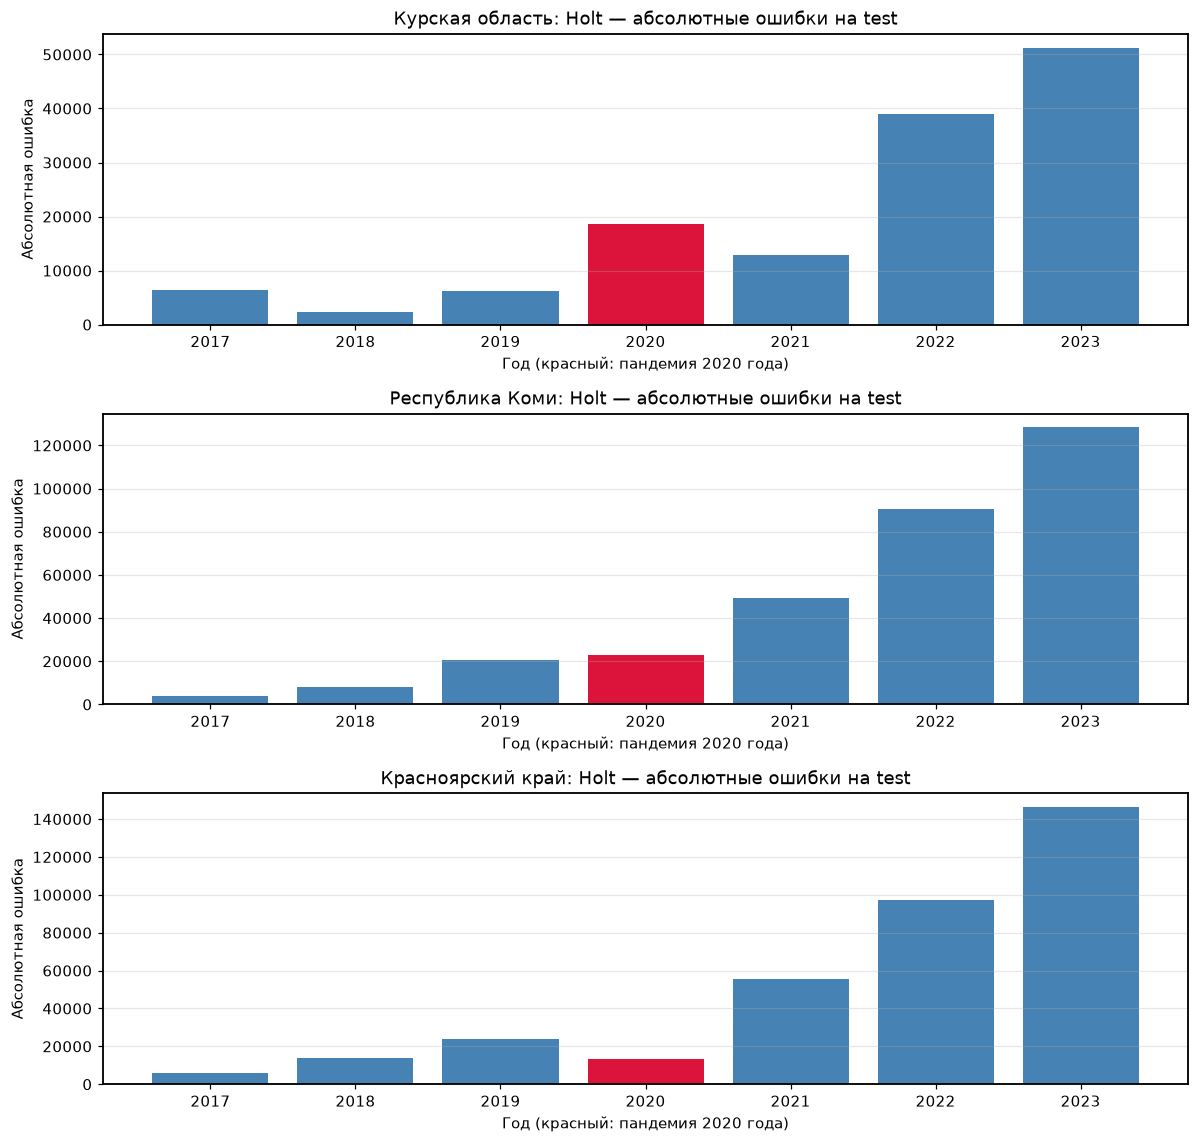

Историческая диагностика событий: отдельные однолетние прогнозы


,Регион,Модель,Год,Событие,Обучение до,Факт,Прогноз на 1 год,Ошибка,Абсолютная ошибка,"Ошибка,%"
0,Курская область,Holt,2008,Начало мирового финансового кризиса,2007,111828.9,106176.30,5652.60,5652.60,5.05
1,Курская область,Holt,2009,Спад после кризиса 2008 года,2008,121783.8,135567.00,-13783.20,13783.20,11.32
2,Курская область,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,339993.3,350665.75,-10672.45,10672.45,3.14
3,Республика Коми,Holt,2008,Начало мирового финансового кризиса,2007,182097.7,180789.90,1307.80,1307.80,0.72
4,Республика Коми,Holt,2009,Спад после кризиса 2008 года,2008,190292.4,209812.50,-19520.10,19520.10,10.26
5,Республика Коми,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,430627.3,428765.34,1861.96,1861.96,0.43
6,Красноярский край,Holt,2008,Начало мирового финансового кризиса,2007,159827.7,136207.40,23620.30,23620.30,14.78
7,Красноярский край,Holt,2009,Спад после кризиса 2008 года,2008,164230.3,156037.72,8192.58,8192.58,4.99
8,Красноярский край,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,373693.6,366667.74,7025.86,7025.86,1.88



Курская область: максимальная ошибка на test — 2023 год, 51276.50 (10.73%).
2020: место 3 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 18705.50.
2008–2009: вне test; см. отдельную таблицу однолетних прогнозов.

Республика Коми: максимальная ошибка на test — 2023 год, 128353.03 (21.59%).
2020: место 4 из 7 по абсолютной ошибке, входит в топ‑5; прогноз недооценил показатель. Абсолютная ошибка — 22862.17.
2008–2009: вне test; см. отдельную таблицу однолетних прогнозов.

Красноярский край: максимальная ошибка на test — 2023 год, 146245.95 (26.29%).
2020: место 6 из 7 по абсолютной ошибке, не входит в топ‑5; прогноз недооценил показатель. Абсолютная ошибка — 13445.16.
2008–2009: вне test; см. отдельную таблицу однолетних прогнозов.


In [15]:
# Ошибки сохранённого тестового прогноза: без повторного обучения.
error_frames = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    _, test = splits[name]
    pred = np.asarray(forecasts_test[name][best_name], dtype=float)
    if pred.shape != (len(test),):
        raise ValueError(f"{name}: длина прогноза не совпадает с test")
    errors = pd.DataFrame({
        "Регион": name, "Модель": best_name,
        "Год": test.index.year, "Факт": test.to_numpy(), "Прогноз": pred,
    })
    errors["Ошибка"] = errors["Факт"] - errors["Прогноз"]
    errors["Абсолютная ошибка"] = errors["Ошибка"].abs()
    errors["Ошибка,%"] = (
        errors["Абсолютная ошибка"] / errors["Факт"].abs().replace(0, np.nan) * 100
    )
    errors = errors.sort_values(
        ["Абсолютная ошибка", "Год"], ascending=[False, True]
    ).reset_index(drop=True)
    errors["Место"] = np.arange(1, len(errors) + 1)
    error_frames.append(errors)

errors_df = pd.concat(error_frames, ignore_index=True)
top5_errors_df = errors_df.loc[errors_df["Место"].le(5)].copy()
print("Топ‑5 ошибок лучшей модели каждого региона на тестовой выборке:")
display(top5_errors_df.round(2))

fig, axes = plt.subplots(
    len(forecast_regions), 1, figsize=(11, 3.5 * len(forecast_regions)), squeeze=False
)
for ax, (name, group) in zip(axes[:, 0], errors_df.groupby("Регион", sort=False)):
    group = group.sort_values("Год")
    colors = ["crimson" if year == 2020 else "steelblue" for year in group["Год"]]
    ax.bar(group["Год"], group["Абсолютная ошибка"], color=colors)
    ax.set_title(f"{name}: {group['Модель'].iloc[0]} — абсолютные ошибки на test")
    ax.set_xticks(group["Год"])
    ax.set_ylabel("Абсолютная ошибка")
    ax.set_xlabel("Год (красный: пандемия 2020 года)")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

# Сопоставление событий при одинаковом однолетнем горизонте.
event_labels = {
    2008: "Начало мирового финансового кризиса",
    2009: "Спад после кризиса 2008 года",
    2020: "Пандемия COVID-19 и ограничения активности",
}
event_rows = []
for name, series in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    for year, event in event_labels.items():
        date = pd.Timestamp(year=year, month=1, day=1)
        history = series.loc[series.index < date]
        if date not in series.index or len(history) < 4:
            continue
        actual = float(series.loc[date])
        prediction = float(np.asarray(MODELS[best_name](history, 1))[0])
        if not np.isfinite(prediction):
            raise ValueError(f"{name}, {year}: некорректный прогноз")
        event_rows.append({
            "Регион": name, "Модель": best_name, "Год": year,
            "Событие": event, "Обучение до": history.index[-1].year,
            "Факт": actual, "Прогноз на 1 год": prediction,
            "Ошибка": actual - prediction,
            "Абсолютная ошибка": abs(actual - prediction),
            "Ошибка,%": mape([actual], [prediction]),
        })
event_errors_df = pd.DataFrame(event_rows)
print("Историческая диагностика событий: отдельные однолетние прогнозы")
display(event_errors_df.round(2))

for name, group in errors_df.groupby("Регион", sort=False):
    worst = group.loc[group["Место"].eq(1)].iloc[0]
    print(f"\n{name}: максимальная ошибка на test — {int(worst['Год'])} год, "
          f"{worst['Абсолютная ошибка']:.2f} ({worst['Ошибка,%']:.2f}%).")
    pandemic = group.loc[group["Год"].eq(2020)]
    if not pandemic.empty:
        row = pandemic.iloc[0]
        position = int(row["Место"])
        inclusion = "входит" if position <= 5 else "не входит"
        direction = "недооценил" if row["Ошибка"] > 0 else "переоценил" if row["Ошибка"] < 0 else "точно предсказал"
        print(f"2020: место {position} из {len(group)} по абсолютной ошибке, "
              f"{inclusion} в топ‑5; прогноз {direction} показатель. "
              f"Абсолютная ошибка — {row['Абсолютная ошибка']:.2f}.")
    print("2008–2009: вне test; см. отдельную таблицу однолетних прогнозов.")


### Интерпретация

Сопоставление с 2008–2009 и 2020 годами показывает совпадение ошибки с периодом экономического шока, но само по себе не доказывает причинную связь. Для 2020 года следует учитывать и ранг ошибки среди остальных тестовых лет: пандемийный год не обязательно даёт максимальную ошибку. Прогноз этапа 5 строился из конца 2016 года сразу на семь лет; ошибки зависят также от горизонта и накопленного отклонения тренда.

В дополнительной таблице горизонт одинаковый — один год, но длина истории обучения различается. Значения показателя представлены в текущих ценах: изменение номинального потребления сочетает динамику объёма и цен. Поэтому абсолютные ошибки разных лет и регионов полезно рассматривать вместе с процентными ошибками. По этим данным нельзя отдельно оценить вклад инфляции, пандемии или финансового кризиса.
